In [42]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

In [93]:
import scipy.stats as st
import statsmodels.api as sm
from statsmodels.formula.api import ols
from statsmodels.stats.multicomp import pairwise_tukeyhsd

In [32]:
sns.set_theme()

In [34]:
def find_outliers_IQR(df):
    
    q1=df.quantile(0.25)
    q3=df.quantile(0.75)
    IQR=q3-q1
    outliers = df[((df<(q1-1.5*IQR)) | (df>(q3+1.5*IQR)))]
    return outliers

In [15]:
sheet_id = '181kv-Uk9HZlUyy5FGZWmSvR1abHHC9-3gG19A9AUt3M'
sheet_name = '1'
url = f'https://docs.google.com/spreadsheets/d/{sheet_id}/gviz/tq?tqx=out:csv&sheet={sheet_name}'
exp1 = pd.read_csv(url)

In [20]:
exp1

,family,number,cup,mode,exposure,total,dead_fert,alive_fert,perc_fert,hatched,per_hatched,swim,perc_swim,per_swim/total,avg_in_groups
0,mix,1,1,control,0,36,3,33,91.66666667,31,93.93939394,31,93.93939394,86.11111111,79.43493761
1,mix,2,2,control,0,44,3,41,93.18181818,41,100,34,82.92682927,77.27272727,NaN
2,mix,3,3,control,0,34,4,30,88.23529412,30,100,30,100,88.23529412,NaN
3,mix,4,4,control,0,45,5,40,88.88888889,36,90,34,85,75.55555556,NaN
4,mix,5,5,control,0,40,8,32,80,30,93.75,28,87.5,70,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
115,mix,116,1,shock_hyp40,40,50,4,46,92,0,0,0,0,0,0
116,mix,117,2,shock_hyp40,40,45,3,42,93.33333333,0,0,0,0,0,NaN
117,mix,118,3,shock_hyp40,40,58,55,3,5.172413793,0,0,0,0,0,NaN
118,mix,119,4,shock_hyp40,40,59,1,58,98.30508475,0,0,0,0,0,NaN


In [5]:
exp1.columns

Index(['family', 'number', 'cup', 'mode', 'exposure', 'total', 'dead_fert',
       'alive_fert', 'perc_fert', 'hatched', 'per_hatched', 'swim',
       'perc_swim', 'per_swim/total', 'avg_in_groups', 'Unnamed: 15',
       'Unnamed: 16', 'Unnamed: 17', 'Unnamed: 18', 'Unnamed: 19',
       'Unnamed: 20', 'Unnamed: 21', 'Unnamed: 22', 'Unnamed: 23',
       'Unnamed: 24', 'Unnamed: 25'],
      dtype='object')

In [16]:
exp1 = exp1[['family', 'number', 'cup', 'mode', 'exposure', 'total', 'dead_fert',
       'alive_fert', 'perc_fert', 'hatched', 'per_hatched', 'swim',
       'perc_swim', 'per_swim/total', 'avg_in_groups']]

In [28]:
exp1['perc_fert'] = exp1.loc[:,'perc_fert'].str.replace(',', '.').astype('float')
exp1['per_hatched'] = exp1.loc[:,'per_hatched'].str.replace(',', '.').astype('float')
exp1['perc_swim'] = exp1.loc[:,'perc_swim'].str.replace(',', '.').astype('float')
exp1['per_swim/total'] = exp1.loc[:,'per_swim/total'].str.replace(',', '.').astype('float')
exp1['avg_in_groups'] = exp1.loc[:,'avg_in_groups'].str.replace(',', '.').astype('float')

### 1. fertilization in CONTROL, MUT2 and MUT5

/var/folders/lr/tz5w155s1wv9t8nfchl8bm700000gn/T/ipykernel_98015/3493507407.py:5: FutureWarning: Passing `palette` without assigning `hue` is deprecated.
  sns.stripplot(data=exp1, x='mut', y='perc_fert',


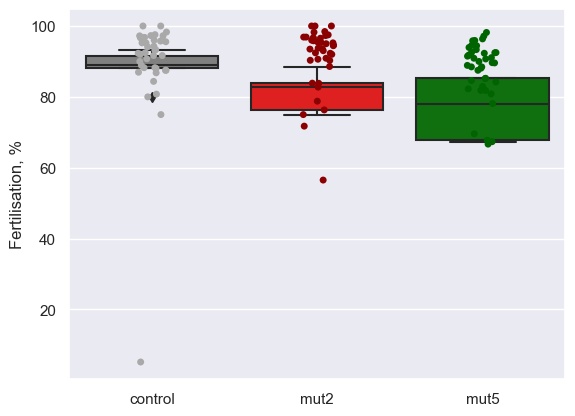

In [127]:
sns.boxplot(data=exp1, x='mode', y='perc_fert',
            order=['control', 'mut2', 'mut5'],
           palette={'control': 'grey', 'mut2': 'red', 'mut5': 'green'})

sns.stripplot(data=exp1, x='mut', y='perc_fert',
            order=['control', 'mut2', 'mut5'],
           palette={'control': 'darkgrey', 'mut2': 'darkred', 'mut5': 'darkgreen'}) 

plt.xlabel("")
plt.ylabel("Fertilisation, %");

In [ ]:
def get_mut_mode(mode):
    if 'mut2' in mode:
        return 'mut2'
    elif 'mut5' in mode:
        return 'mut5'
    else:
        return 'control'

exp1['mut_mode'] = exp1['mode'].apply(lambda x: )

### 2. hatched in groups == mode

In [63]:
exp1['mode'].unique()

array(['control', 'mut2', 'mut2_shock40', 'mut2_hyp20', 'mut2_hyp40',
       'mut2_hyp60', 'mut2_shock_hyp10', 'mut2_shock_hyp20',
       'mut2_shock_hyp40', 'mut5', 'mut5_shock40', 'mut5_hyp20',
       'mut5_hyp40', 'mut5_hyp60', 'mut5_shock_hyp10', 'mut5_shock_hyp20',
       'mut5_shock_hyp40', 'shock40', 'hyp20', 'hyp40', 'hyp60',
       'shock_hyp10', 'shock_hyp20', 'shock_hyp40'], dtype=object)

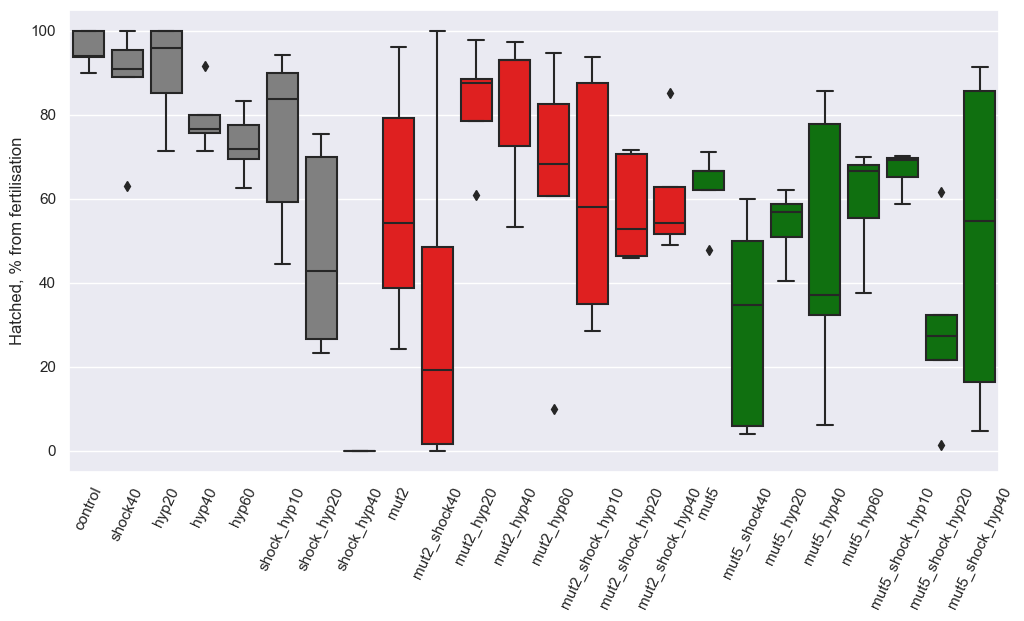

In [120]:
plt.figure(figsize=(12,6))
sns.boxplot(data=exp1, x='mode', y='per_hatched',
                       order=['control', 'shock40', 'hyp20', 'hyp40', 'hyp60', 'shock_hyp10', 'shock_hyp20', 'shock_hyp40', 
                   'mut2', 'mut2_shock40', 'mut2_hyp20', 'mut2_hyp40', 
                   'mut2_hyp60', 'mut2_shock_hyp10', 'mut2_shock_hyp20', 
                   'mut2_shock_hyp40', 'mut5', 'mut5_shock40', 'mut5_hyp20', 
                   'mut5_hyp40', 'mut5_hyp60', 'mut5_shock_hyp10', 'mut5_shock_hyp20', 'mut5_shock_hyp40'],
           palette={'control': 'grey', 'shock40': 'grey', 'hyp20': 'grey', 'hyp40': 'grey', 'hyp60': 'grey', 
                    'shock_hyp10': 'grey', 'shock_hyp20': 'grey', 'shock_hyp40': 'grey', 
                   'mut2': 'red', 'mut2_shock40': 'red', 'mut2_hyp20': 'red', 'mut2_hyp40': 'red', 
                   'mut2_hyp60': 'red', 'mut2_shock_hyp10': 'red', 'mut2_shock_hyp20': 'red', 
                   'mut2_shock_hyp40': 'red', 'mut5': 'green', 'mut5_shock40': 'green', 'mut5_hyp20': 'green', 
                   'mut5_hyp40': 'green', 'mut5_hyp60': 'green', 'mut5_shock_hyp10': 'green', 
                    'mut5_shock_hyp20': 'green', 'mut5_shock_hyp40': 'green'})

plt.xlabel("")
plt.ylabel("Hatched, % from fertilisation")
plt.xticks(rotation=65);

In [72]:
exp1['mut'] = exp1['mode'].map(lambda x: x[0:4] if 'mut' in x else 'control')
exp1['shock'] = exp1['mode'].map(lambda x: 1 if 'shock' in x else 0)
exp1['hyp'] = exp1['mode'].map(lambda x: 1 if 'hyp' in x else 0)

In [85]:
model = ols("""per_hatched ~ mut + shock + hyp + exposure +
               mut:shock + mut:hyp + mut:exposure + shock:hyp + shock:exposure + hyp:exposure +
               mut:shock:hyp + mut:shock:exposure + mut:hyp:exposure + shock:hyp:exposure +
               mut:shock:hyp:exposure""", data=exp1).fit()

sm.stats.anova_lm(model, typ=2)

,sum_sq,df,F,PR(>F)
mut,6.974706e+03,2.0,7.327339e+00,0.001063
shock,1.141349e-12,1.0,2.398109e-15,1.000000
mut:shock,2.376267e-09,2.0,2.496409e-12,1.000000
hyp,4.407206e+00,1.0,9.260059e-03,0.923527
mut:hyp,1.023340e+04,2.0,1.075079e+01,0.000058
exposure,4.481028e-04,1.0,9.415167e-07,0.999228
mut:exposure,-1.697028e-04,2.0,-1.782828e-07,1.000000
shock:hyp,2.496132e+03,1.0,5.244667e+00,0.024073
mut:shock:hyp,3.768631e+03,2.0,3.959169e+00,0.022082
shock:exposure,4.300236e+02,1.0,9.035304e-01,0.344084


In [97]:
print(pairwise_tukeyhsd(exp1['per_hatched'], exp1['mode']))

            Multiple Comparison of Means - Tukey HSD, FWER=0.05            
     group1           group2      meandiff p-adj    lower    upper   reject
---------------------------------------------------------------------------
         control            hyp20  -5.0485    1.0  -56.0975  46.0005  False
         control            hyp40  -16.434 0.9999   -67.483   34.615  False
         control            hyp60 -22.5901 0.9922  -73.6391  28.4589  False
         control             mut2 -37.0709 0.5092  -88.1199  13.9781  False
         control       mut2_hyp20 -12.8391    1.0  -63.8881  38.2099  False
         control       mut2_hyp40 -13.6427    1.0  -64.6917  37.4064  False
         control       mut2_hyp60 -32.3185 0.7617  -83.3675  18.7305  False
         control     mut2_shock40 -61.6871 0.0037 -112.7361 -10.6381   True
         control mut2_shock_hyp10 -34.9839  0.624   -86.033  16.0651  False
         control mut2_shock_hyp20 -38.0221 0.4578  -89.0711  13.0269  False
         con

the difference is statistically significant between:   
control            mut2_shock40   
control            mut5_shock40   
control            mut5_shock_hyp20   
control            shock_hyp40   
hyp20              mut2_shock40   
hyp20              mut5_shock40   
hyp20              mut5_shock_hyp20    
hyp20              shock_hyp40   
hyp40              shock_hyp40   
hyp60              shock_hyp40   
mut2               shock_hyp40   
mut2_hyp20         mut5_shock40   
mut2_hyp20         mut5_shock_hyp20   
mut2_hyp20         shock_hyp40   
mut2_hyp40         mut5_shock_hyp20   
mut2_hyp40         shock_hyp40   
mut2_hyp60         shock_hyp40   
mut2_shock40       shock40   
mut2_shock_hyp10   shock_hyp40   
mut2_shock_hyp20   shock_hyp40   
mut2_shock_hyp40   shock_hyp40   
mut5               shock_hyp40   
mut5_hyp20         shock_hyp40   
mut5_hyp60         shock_hyp40   
mut5_shock40       shock40   
mut5_shock_hyp10   shock_hyp40   
mut5_shock_hyp20   shock40   
shock40            shock_hyp40   
shock_hyp10        shock_hyp40   

### 3. swim in groups == mode

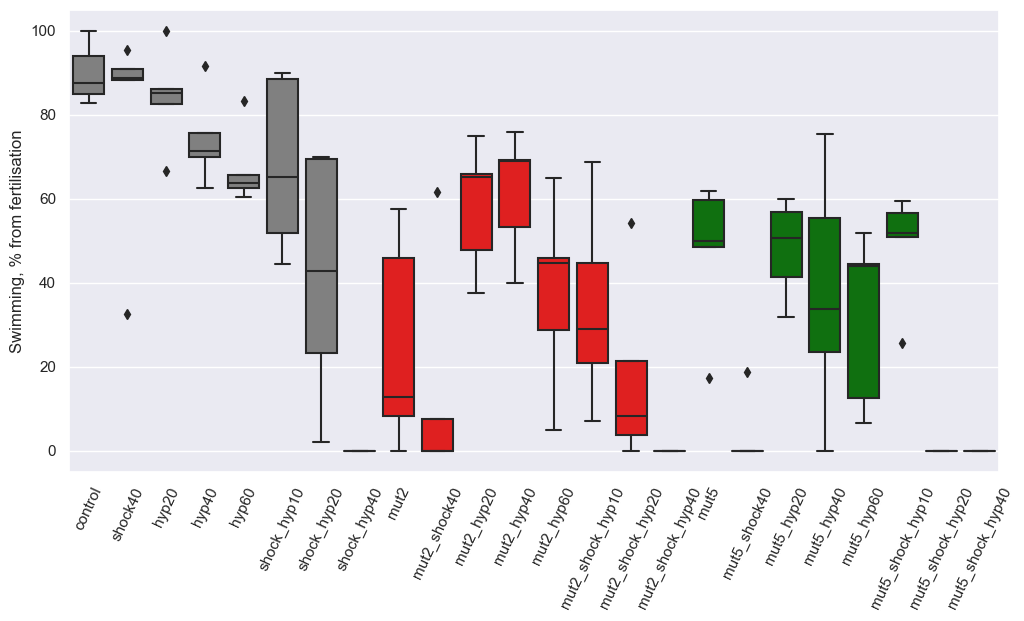

In [88]:
plt.figure(figsize=(12,6))
sns.boxplot(data=exp1, x='mode', y='perc_swim',
            order=['control', 'shock40', 'hyp20', 'hyp40', 'hyp60', 'shock_hyp10', 'shock_hyp20', 'shock_hyp40', 
                   'mut2', 'mut2_shock40', 'mut2_hyp20', 'mut2_hyp40', 
                   'mut2_hyp60', 'mut2_shock_hyp10', 'mut2_shock_hyp20', 
                   'mut2_shock_hyp40', 'mut5', 'mut5_shock40', 'mut5_hyp20', 
                   'mut5_hyp40', 'mut5_hyp60', 'mut5_shock_hyp10', 'mut5_shock_hyp20', 'mut5_shock_hyp40'],
           palette={'control': 'grey', 'shock40': 'grey', 'hyp20': 'grey', 'hyp40': 'grey', 'hyp60': 'grey', 
                    'shock_hyp10': 'grey', 'shock_hyp20': 'grey', 'shock_hyp40': 'grey', 
                   'mut2': 'red', 'mut2_shock40': 'red', 'mut2_hyp20': 'red', 'mut2_hyp40': 'red', 
                   'mut2_hyp60': 'red', 'mut2_shock_hyp10': 'red', 'mut2_shock_hyp20': 'red', 
                   'mut2_shock_hyp40': 'red', 'mut5': 'green', 'mut5_shock40': 'green', 'mut5_hyp20': 'green', 
                   'mut5_hyp40': 'green', 'mut5_hyp60': 'green', 'mut5_shock_hyp10': 'green', 
                    'mut5_shock_hyp20': 'green', 'mut5_shock_hyp40': 'green'})

plt.xlabel("")
plt.ylabel("Swimming, % from fertilisation")
plt.xticks(rotation=65);

In [90]:
model = ols("""perc_swim ~ mut + shock + hyp + exposure +
               mut:shock + mut:hyp + mut:exposure + shock:hyp + shock:exposure + hyp:exposure +
               mut:shock:hyp + mut:shock:exposure + mut:hyp:exposure + shock:hyp:exposure +
               mut:shock:hyp:exposure""", data=exp1).fit()

sm.stats.anova_lm(model, typ=2)

,sum_sq,df,F,PR(>F)
mut,3.093920e+04,2.0,4.507185e+01,9.411845e-15
shock,-8.300951e-08,1.0,-2.418545e-10,1.000000e+00
mut:shock,1.432969e-09,2.0,2.087532e-12,1.000000e+00
hyp,8.871732e+01,1.0,2.584846e-01,6.122610e-01
mut:hyp,7.545965e+03,2.0,1.099287e+01,4.749519e-05
exposure,6.528133e-04,1.0,1.902021e-06,9.989023e-01
mut:exposure,-1.302626e-04,2.0,-1.897649e-07,1.000000e+00
shock:hyp,8.408772e+03,1.0,2.449960e+01,2.945518e-06
mut:shock:hyp,1.238821e+03,2.0,1.804699e+00,1.697375e-01
shock:exposure,1.159253e+02,1.0,3.377573e-01,5.624087e-01


In [98]:
print(pairwise_tukeyhsd(exp1['perc_swim'], exp1['mode']))

            Multiple Comparison of Means - Tukey HSD, FWER=0.05            
     group1           group2      meandiff p-adj    lower    upper   reject
---------------------------------------------------------------------------
         control            hyp20  -5.7807    1.0  -48.2394  36.6781  False
         control            hyp40 -15.6027 0.9994  -58.0614  26.8561  False
         control            hyp60 -22.7348 0.9367  -65.1936  19.7239  False
         control             mut2 -64.9208    0.0 -107.3796  -22.462   True
         control       mut2_hyp20 -31.5646 0.4616  -74.0234  10.8941  False
         control       mut2_hyp40 -28.3949 0.6695  -70.8537  14.0639  False
         control       mut2_hyp60  -51.962  0.003  -94.4207  -9.5032   True
         control     mut2_shock40 -76.0271    0.0 -118.4859 -33.5683   True
         control mut2_shock_hyp10 -55.7736 0.0008  -98.2324 -13.3148   True
         control mut2_shock_hyp20 -72.3469    0.0 -114.8057 -29.8882   True
         con